# ZTF Kron photometry: the method, step by step

The filtering compares ZTF and PS1 with the same photometry type on both sides: PSF magnitudes for point sources, Kron magnitudes for extended sources. PS1's Kron magnitudes come from its catalog. ZTF's are measured here, on the deep reference image at every DAOPhot position, with PS1's own radius estimator (psphot's `psphotKronIterate`, read from the IPP source) applied to ZTF pixels, so the two measurements are independent and comparable. The code is `Extracting/kron.py`; each cell below runs one stage and shows its diagnostics.

The recipe:

1. **Background and noise**: `sep` background in 64" boxes; per-pixel variance from IRSA's `refunc`.
2. **Smoothed copy** of the image, Gaussian of σ = 0.9 σ_PSF truncated at 2σ (psphot: 1.7 px on its ~1.9 px PSF). Used only for the radius.
3. **Segmentation seeded at the known positions**: a marker watershed on the smoothed image above 1σ, one marker per DAOPhot source. Deblending follows the catalog; a pixel in another source's basin is masked when measuring this one.
4. **Floor on the radius**: the median plain first moment, inside a 4σ_PSF window, of every source with DAOPhot S/N ≥ 40 (psphot's `MOMENTS_MIN_KRON`: all non-blended sources above 2 × `PSF_SN_LIM`; the sample is star-dominated).
5. **Kron radius**, two passes. Window: the sky radius on the first pass (psphot's `psphotRadialProfileWings`: log-spaced annuli from 4σ_PSF to 15", robust median per annulus, stop where the profile slope flattens below the sky model's rms, interpolating to zero flux, or where the median reaches the sky, or rises), then $\min(6R_1,\ \sqrt{F_{\rm Kron}/(2\pi\sigma_{\rm sky})})$, never below 4σ_PSF. Inside it, the symmetrised first moment on the smoothed image,
   $$R_1 = \frac{\sum_{\rm pairs} \operatorname{sign}(f_1)\sqrt{|f_1 f_2|}\,r}{\sum_{\rm pairs} \tfrac12 (f_1+f_2)},$$
   over mirror-pixel pairs that are both unmasked; floored at the stellar R₁; capped at the window for peaks below S/N 10. If either sum is not positive the source has no measurable extent and gets no Kron magnitude, as in psphot (flagged `FLAG_NO_RADIUS`).
6. **Flux**: whole-pixel sum inside 2.5 R₁ on the unsmoothed image, other basins and bad pixels masked, error √Σvar. No sub-pixel sampling, no aperture correction (as psphot).
7. **Checks** against the DAOPhot PSF magnitudes (stellar locus and its scatter), SExtractor's `MAG_AUTO`, and PS1's catalog Kron on the matched sample, where part of any disagreement can be real.
8. **All bands**, written to the object table as `{b}_zkron*` columns.

Worked in r; the last section runs g, r, i.

In [1]:
import os, sys
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy.nddata import Cutout2D
from astropy.visualization import simple_norm
import astropy.units as u
from Extracting.images import load_ztf_refimg
from Extracting.ztf_images import refimg_path
from Extracting import kron

D = '../Data'
Q = (643, 11, 1)
b = 'r'
def load(bb):
    return load_ztf_refimg(refimg_path(f'{D}/ztf_data', *Q, bb), unc_path=refimg_path(f'{D}/ztf_data', *Q, bb, 'refunc'), cov_path=refimg_path(f'{D}/ztf_data', *Q, bb, 'refcov'))
im = load(b)
obj = pd.read_parquet(f'{D}/ztf_data/ztfobj_643_11_1.parquet')      # merged ZTF objects; {b}_mag etc. are DAOPhot, {b}_kron is MAG_AUTO
ps1 = pd.read_parquet(f'{D}/ztf_data/ps1_643_11_1.parquet')
gaia = pd.read_parquet(f'{D}/ztf_data/gaia_643_11_1.parquet')
print(f'{im.name}: {im.shape[1]}x{im.shape[0]} px, {im.pixel_scale:.3f}"/px, FWHM {im.fwhm_px:.2f} px, zero point {im.zero_point:.3f}, MAGLIM {im.mag_limit}; {im.bad.mean()*100:.1f}% bad pixels')

# Truth sets on the object table: Gaia stars (5-sigma parallax or proper motion, clean astrometry) and PS1 EXT
gi, gsep, _ = SkyCoord(obj.ra.values, obj.dec.values, unit='deg').match_to_catalog_sky(SkyCoord(gaia.ra.values, gaia.dec.values, unit='deg'))
gm = gaia.iloc[gi].reset_index(drop=True)
pm_sig = np.hypot(gm.pmra / gm.pmra_error, gm.pmdec / gm.pmdec_error)
obj['star'] = (gsep < 1 * u.arcsec) & ((gm.parallax_over_error > 5) | (pm_sig > 5)).values & (gm.ruwe < 1.4).values & (gm.ipd_frac_multi_peak < 2).values
obj['ext'] = np.where(obj.ps1_idx >= 0, ((ps1.qualityFlag.astype(int).values & 1) != 0)[obj.ps1_idx.clip(lower=0)], False)
det = (obj[f'{b}_idx'] >= 0).values
mag = obj[f'{b}_mag'].values
star, ext = obj.star.values & det, obj.ext.values & det
print(f'{det.sum()} objects detected in {b}: {star.sum()} Gaia stars, {ext.sum()} PS1 EXT')
mad = lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))
bins = np.arange(14, 23.01, 0.5)
def binned(x, y, sel, stat=np.median, nmin=20):
    out, n = [], []
    for lo in bins[:-1]:
        s = sel & (x >= lo) & (x < lo + 0.5) & np.isfinite(y)
        out.append(stat(y[s]) if s.sum() >= nmin else np.nan); n.append(s.sum())
    return bins[:-1] + 0.25, np.array(out), np.array(n)

CasJobs will use the credentials from mast_dino_login.txt


ztf_000643_zr_c11_q1: 3200x3200 px, 1.000"/px, FWHM 1.69 px, zero point 26.275, MAGLIM 23.67; 9.7% bad pixels
62442 objects detected in r: 14212 Gaia stars, 3222 PS1 EXT


## Steps 1 to 3. Background, noise, smoothing and the catalog-seeded segmentation

`kron.prepare` does all three. The noise is not estimated from the image: `refunc` gives the 1σ uncertainty of every coadd pixel, so aperture errors below are √Σσ² over the aperture; the check is that it agrees with the empirical background rms in the typical pixel. The segmentation puts one marker at each DAOPhot position and grows basins over the pixels more than 1σ above sky in the smoothed image, so every catalog source owns a segment and two sources are always split at the saddle between them.

sigma_PSF 0.72 px; background rms 0.92 DN, median refunc 0.77 DN; smoothed-image rms 0.71 DN
99760 segments (one per source inside the image), covering 22.5% of pixels; 100.0% of detected objects inside the image


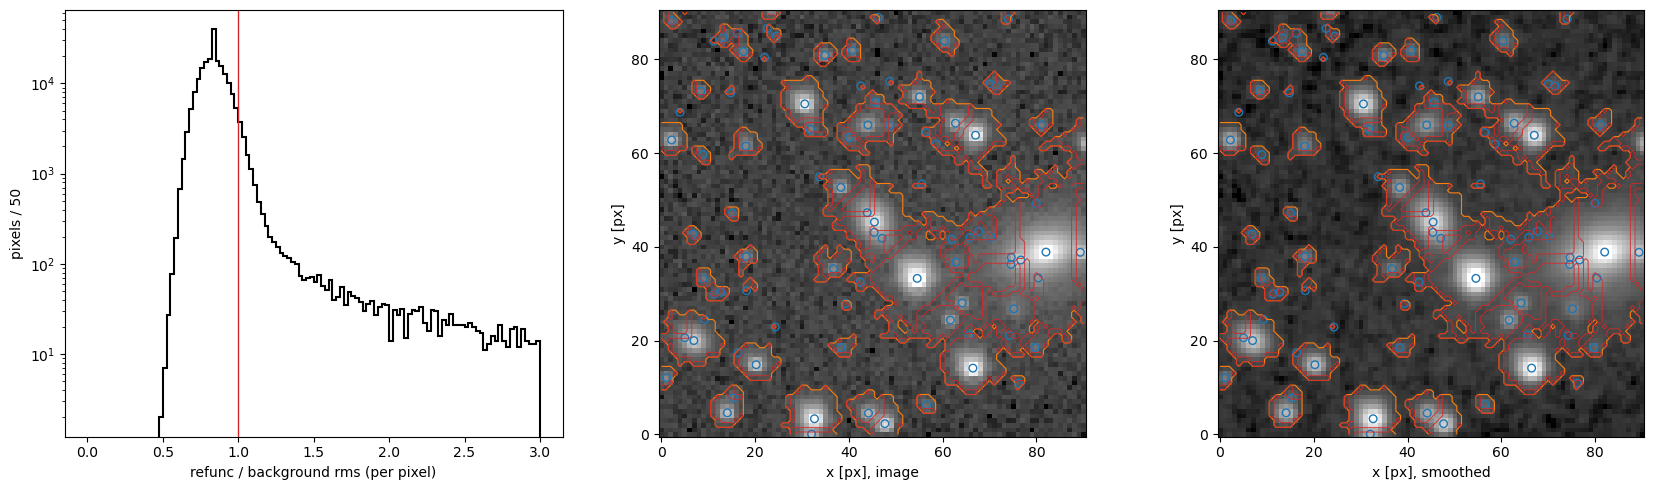

In [2]:
frame = kron.prepare(im, obj.ra.values, obj.dec.values)
print(f'sigma_PSF {frame.sigma_psf:.2f} px; background rms {frame.sigma_sky:.2f} DN, median refunc {np.nanmedian(np.sqrt(frame.var)):.2f} DN; smoothed-image rms {frame.sigma_smooth:.2f} DN')
seg_px = (frame.segmap > 0).mean(); n_seg = len(np.unique(frame.segmap)) - 1
print(f'{n_seg} segments (one per source inside the image), covering {100*seg_px:.1f}% of pixels; {100*frame.inside[det].mean():.1f}% of detected objects inside the image')
pad = frame.pad
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ratio = np.sqrt(frame.var[pad:-pad, pad:-pad]) / frame.sigma_sky
axes[0].hist(ratio[np.isfinite(ratio)].ravel()[::50], bins=np.linspace(0, 3, 121), histtype='step', color='k', lw=1.5)
axes[0].axvline(1, color='C3', lw=1); axes[0].set_xlabel('refunc / background rms (per pixel)'); axes[0].set_ylabel('pixels / 50'); axes[0].set_yscale('log')
# a 90" cutout of a galaxy: smoothed image with basin boundaries and the DAOPhot positions
k = np.flatnonzero(ext & (mag > 17) & (mag < 18.5) & frame.inside)[3]
x0, y0 = int(round(frame.x[k])), int(round(frame.y[k])); h = 45
sl = (slice(y0 - h, y0 + h + 1), slice(x0 - h, x0 + h + 1))
for ax, img, lab in ((axes[1], frame.sub[sl], 'image'), (axes[2], frame.smooth[sl], 'smoothed')):
    ax.imshow(img, origin='lower', cmap='gray', norm=simple_norm(img, 'log', percent=99.5))
    seg = frame.segmap[sl]
    ax.contour(seg > 0, levels=[0.5], colors='C1', linewidths=0.8)
    edges = (np.diff(seg, axis=0, prepend=seg[:1]) != 0) | (np.diff(seg, axis=1, prepend=seg[:, :1]) != 0)
    ax.contour(edges & (seg > 0), levels=[0.5], colors='C3', linewidths=0.6)
    inside = (frame.x > x0 - h) & (frame.x < x0 + h) & (frame.y > y0 - h) & (frame.y < y0 + h)
    ax.scatter(frame.x[inside] - (x0 - h), frame.y[inside] - (y0 - h), s=30, facecolors='none', edgecolors='C0', lw=1)
    ax.set_xlabel(f'x [px], {lab}'); ax.set_ylabel('y [px]')
plt.tight_layout(); plt.show()

## Step 4. The floor

psphot's `MOMENTS_MIN_KRON`: the median of the ordinary first moment Σ f r / Σ f, inside a 4σ_PSF window on the unsmoothed image, over every non-blended source with S/N ≥ 2 × `PSF_SN_LIM` = 40. No star selection; at that S/N the sample is almost all stars and the median is robust to the galaxies in it. It is the smallest radius any source is allowed, and it is what keeps the faint end stable: a faint point source's own moment scatters around this value and noise would otherwise push it below.

10507 sources with S/N >= 40 (93% Gaia stars, 0% PS1 EXT): plain moment median 1.09 px = 1.09" (Gaussian PSF would give 0.90 px); point-source aperture 2.5 R1 = 2.73"
the same sample restricted to Gaia stars: median 1.09 px


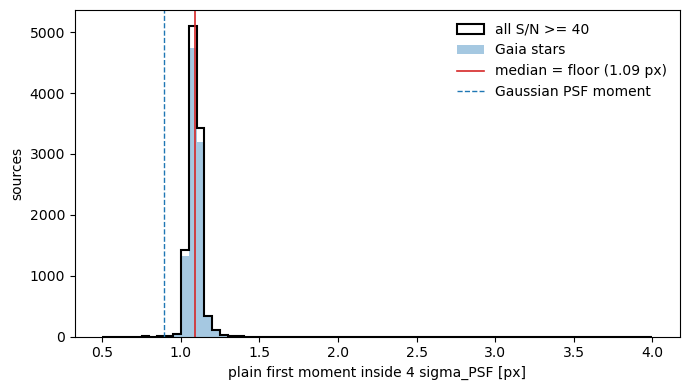

In [3]:
snr = np.nan_to_num(obj[f'{b}_snr'].values, nan=0.0)
r_min = kron.moment_floor(frame, snr)
floor_sel = frame.inside & (snr >= kron.FLOOR_SNR)
w = kron.MIN_WINDOW_SIGMA * frame.sigma_psf
r1_floor = np.array([kron.plain_moment(frame, k, w) for k in np.flatnonzero(floor_sel)])
print(f'{floor_sel.sum()} sources with S/N >= {kron.FLOOR_SNR:.0f} ({100*star[floor_sel].mean():.0f}% Gaia stars, {100*ext[floor_sel].mean():.0f}% PS1 EXT): plain moment median {r_min:.2f} px = {r_min*im.pixel_scale:.2f}" (Gaussian PSF would give {0.53*im.fwhm_px:.2f} px); point-source aperture 2.5 R1 = {kron.KRON_FACTOR*r_min*im.pixel_scale:.2f}"')
print(f'the same sample restricted to Gaia stars: median {np.nanmedian(r1_floor[star[floor_sel]]):.2f} px')
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(r1_floor[np.isfinite(r1_floor)], bins=np.linspace(0.5, 4, 71), histtype='step', color='k', lw=1.5, label='all S/N >= 40')
ax.hist(r1_floor[np.isfinite(r1_floor) & star[floor_sel]], bins=np.linspace(0.5, 4, 71), histtype='stepfilled', color='C0', alpha=0.4, label='Gaia stars')
ax.axvline(r_min, color='C3', lw=1.2, label=f'median = floor ({r_min:.2f} px)'); ax.axvline(0.53 * im.fwhm_px, color='C0', ls='--', lw=1, label='Gaussian PSF moment')
ax.set_xlabel('plain first moment inside 4 sigma_PSF [px]'); ax.set_ylabel('sources'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Steps 5 and 6. Kron radius and flux for every source

`kron.kron_photometry` runs the two passes. Diagnostics: the sky radius (first window) and R₁ against magnitude for stars and extended sources, how often the floor and the faint cap fire and how many sources have no defined moment (no Kron), and the fraction of each aperture that was masked.

measured 54663 of 62442 detected objects (87.5%); MAG_AUTO exists for 47%
  moment undefined: no Kron       :  12.3% of all,   0.5% of Gaia stars,   4.9% of EXT
  R1 at the floor                 :  27.2% of all,   5.1% of Gaia stars,  11.3% of EXT
  faint cap at window             :   0.2% of all,   0.0% of Gaia stars,   0.0% of EXT
  aperture truncated at 15"       :   0.1% of all,   0.0% of Gaia stars,   0.0% of EXT
  flux <= 0                       :   0.2% of all,   0.0% of Gaia stars,   0.0% of EXT


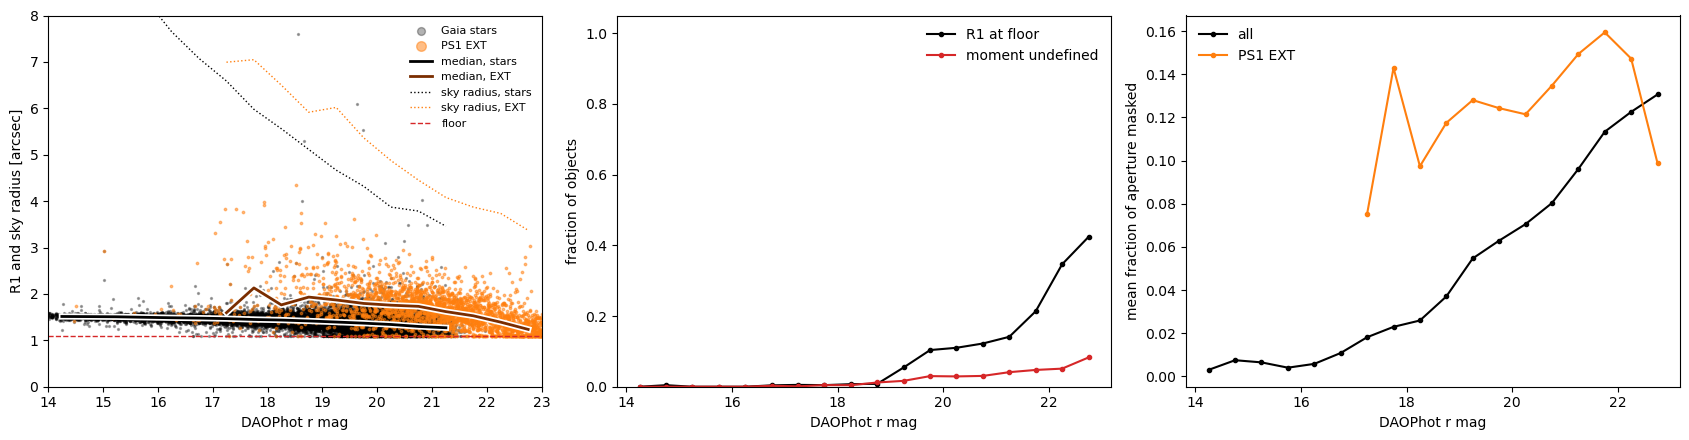

In [4]:
res = kron.kron_photometry(frame, det)
zk, zk_err = res.mag.values, res.magerr.values
flag = res.flag.values; ok = det & np.isfinite(zk)
print(f'measured {ok.sum()} of {det.sum()} detected objects ({100*ok.sum()/det.sum():.1f}%); MAG_AUTO exists for {100*np.isfinite(obj[f"{b}_kron"].values[det]).mean():.0f}%')
for bit, name in ((kron.FLAG_NO_RADIUS, 'moment undefined: no Kron'), (kron.FLAG_AT_FLOOR, 'R1 at the floor'), (kron.FLAG_FAINT_CAP, 'faint cap at window'), (kron.FLAG_TRUNCATED, 'aperture truncated at 15"'), (kron.FLAG_NEGATIVE, 'flux <= 0')):
    f = (flag & bit) != 0
    print(f'  {name:32s}: {100*f[det].mean():5.1f}% of all, {100*f[star].mean():5.1f}% of Gaia stars, {100*f[ext].mean():5.1f}% of EXT')
c, r1_s, _ = binned(mag, res.r1.values, star); c, r1_e, _ = binned(mag, res.r1.values, ext)
c, sky_s, _ = binned(mag, res.sky_radius.values, star); c, sky_e, _ = binned(mag, res.sky_radius.values, ext)
c, floor_f, _ = binned(mag, ((flag & kron.FLAG_AT_FLOOR) != 0).astype(float), det, np.mean)
c, nor_f, _ = binned(mag, ((flag & kron.FLAG_NO_RADIUS) != 0).astype(float), det, np.mean)
c, msk, _ = binned(mag, res.masked_frac.values, ok, np.mean); c, msk_e, _ = binned(mag, res.masked_frac.values, ok & ext, np.mean)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(mag[star], res.r1.values[star], s=2, alpha=0.3, color='k', label='Gaia stars'); axes[0].scatter(mag[ext], res.r1.values[ext], s=3, alpha=0.5, color='C1', label='PS1 EXT')
axes[0].plot(c, r1_s, 'w-', lw=4.5); axes[0].plot(c, r1_s, 'k-', lw=2, label='median, stars'); axes[0].plot(c, r1_e, 'w-', lw=4.5); axes[0].plot(c, r1_e, '-', color='#7a2d00', lw=2, label='median, EXT')
axes[0].plot(c, sky_s, 'k:', lw=1, label='sky radius, stars'); axes[0].plot(c, sky_e, 'C1:', lw=1, label='sky radius, EXT')
axes[0].axhline(r_min * im.pixel_scale, color='C3', ls='--', lw=1, label='floor')
axes[0].set_xlim(14, 23); axes[0].set_ylim(0, 8); axes[0].set_xlabel(f'DAOPhot {b} mag'); axes[0].set_ylabel('R1 and sky radius [arcsec]'); axes[0].legend(frameon=False, fontsize=8, markerscale=4)
axes[1].plot(c, floor_f, 'k.-', label='R1 at floor'); axes[1].plot(c, nor_f, 'C3.-', label='moment undefined'); axes[1].set_xlabel(f'DAOPhot {b} mag'); axes[1].set_ylabel('fraction of objects'); axes[1].set_ylim(0, 1.05); axes[1].legend(frameon=False)
axes[2].plot(c, msk, 'k.-', label='all'); axes[2].plot(c, msk_e, 'C1.-', label='PS1 EXT'); axes[2].set_xlabel(f'DAOPhot {b} mag'); axes[2].set_ylabel('mean fraction of aperture masked'); axes[2].legend(frameon=False)
plt.tight_layout(); plt.show()

## Step 7. Checks

1. **Stellar locus**: DAOPhot PSF − our Kron for Gaia stars, with its scatter against the catalog error √(σ²_PSF + σ²_Kron). The morphology rule reads this on the ZTF side, so the floor 0.05 has to sit above the locus and the error has to describe the scatter.
2. **Ours vs `MAG_AUTO`** for stars and extended sources.
3. **ZTF − PS1 Kron** on the matched sample, same objects for each ZTF option (ours, `MAG_AUTO`), with the PSF − PSF comparison alongside. Lower scatter for extended sources is the figure of merit, remembering that a source whose morphology changed contributes real scatter here.

      mag   n* PSF-ours * scatter * cat err * PSF-ours EXT  ours-AUTO * ours-AUTO EXT
14.0-14.5  152     -0.050     0.007     0.019              +0.004±0.011              
14.5-15.0  200     -0.050     0.007     0.019              +0.003±0.010              
15.0-15.5  291     -0.050     0.008     0.019              -0.000±0.012              
15.5-16.0  404     -0.050     0.009     0.020              -0.002±0.012              
16.0-16.5  587     -0.051     0.009     0.020              -0.005±0.012              
16.5-17.0  708     -0.049     0.011     0.021              -0.008±0.014              
17.0-17.5  897     -0.049     0.015     0.021       +0.108 -0.011±0.014  +0.005±0.038
17.5-18.0 1019     -0.049     0.017     0.021       +0.372 -0.013±0.016  +0.023±0.081
18.0-18.5 1274     -0.049     0.024     0.022       +0.286 -0.017±0.020  -0.004±0.057
18.5-19.0 1422     -0.047     0.035     0.023       +0.348 -0.023±0.024  -0.005±0.060
19.0-19.5 1653     -0.049     0.048     0.025       +0

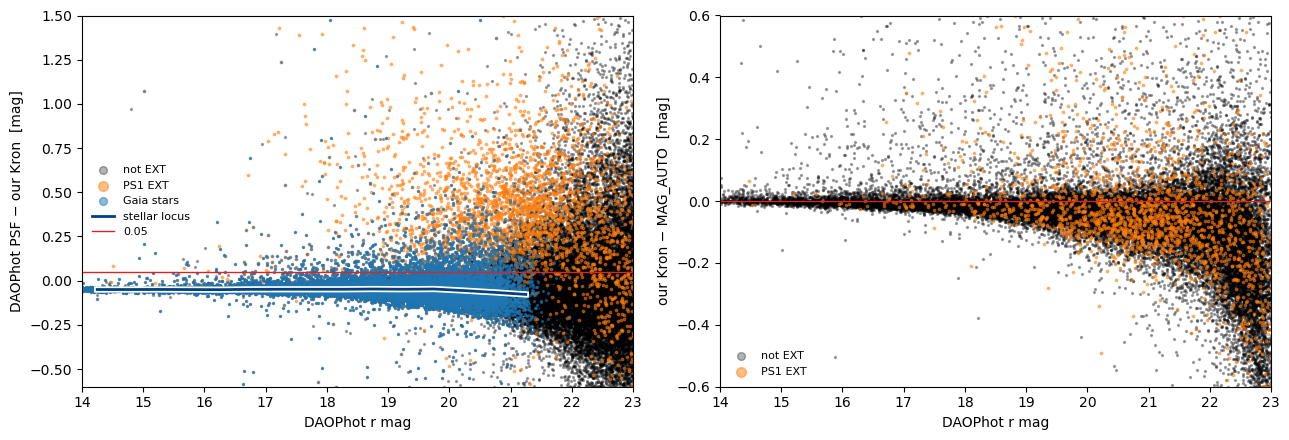


ZTF − PS1, common subset of 27122 matched objects: median ± robust scatter
  16-19 point n= 5536  ours − PS1 Kron: -0.082±0.038   MAG_AUTO − PS1 Kron: -0.073±0.042   PSF − PSF: -0.061±0.048
  16-19 EXT   n=  135  ours − PS1 Kron: -0.101±0.102   MAG_AUTO − PS1 Kron: -0.138±0.129   PSF − PSF: -0.252±0.204
  19-21 point n= 6389  ours − PS1 Kron: -0.152±0.091   MAG_AUTO − PS1 Kron: -0.122±0.090   PSF − PSF: -0.093±0.073
  19-21 EXT   n=  556  ours − PS1 Kron: -0.161±0.119   MAG_AUTO − PS1 Kron: -0.138±0.113   PSF − PSF: -0.438±0.156
  21-22 point n= 4666  ours − PS1 Kron: -0.235±0.178   MAG_AUTO − PS1 Kron: -0.181±0.177   PSF − PSF: -0.147±0.109
  21-22 EXT   n=  548  ours − PS1 Kron: -0.223±0.160   MAG_AUTO − PS1 Kron: -0.180±0.174   PSF − PSF: -0.435±0.122
  22-23 point n= 6210  ours − PS1 Kron: -0.279±0.337   MAG_AUTO − PS1 Kron: -0.158±0.356   PSF − PSF: -0.199±0.168
  22-23 EXT   n=  485  ours − PS1 Kron: -0.261±0.368   MAG_AUTO − PS1 Kron: -0.184±0.360   PSF − PSF: -0.348±0.225
cove

In [5]:
auto, auto_err = obj[f'{b}_kron'].values, obj[f'{b}_kronerr'].values
psf, psf_err = obj[f'{b}_mag'].values, obj[f'{b}_magerr'].values
d_loc, e_loc, d_auto = psf - zk, np.hypot(psf_err, zk_err), zk - auto
rows = []
for lo in bins[:-1]:
    r = ok & (mag >= lo) & (mag < lo + 0.5); s, e = r & star, r & ext; sa = s & np.isfinite(auto); ea = e & np.isfinite(auto)
    if s.sum() < 30: continue
    rows.append({'mag': f'{lo:.1f}-{lo+.5:.1f}', 'n*': s.sum(), 'PSF-ours *': f'{np.median(d_loc[s]):+.3f}', 'scatter *': f'{mad(d_loc[s]):.3f}', 'cat err *': f'{np.median(e_loc[s]):.3f}',
                 'PSF-ours EXT': f'{np.median(d_loc[e]):+.3f}' if e.sum() >= 20 else '', 'ours-AUTO *': f'{np.median(d_auto[sa]):+.3f}±{mad(d_auto[sa]):.3f}' if sa.sum() >= 20 else '', 'ours-AUTO EXT': f'{np.median(d_auto[ea]):+.3f}±{mad(d_auto[ea]):.3f}' if ea.sum() >= 20 else ''})
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
axes[0].scatter(mag[ok & ~ext], d_loc[ok & ~ext], s=2, alpha=0.3, color='k', label='not EXT'); axes[0].scatter(mag[ok & ext], d_loc[ok & ext], s=3, alpha=0.5, color='C1', label='PS1 EXT'); axes[0].scatter(mag[ok & star], d_loc[ok & star], s=2, alpha=0.5, color='C0', label='Gaia stars')
c, loc, _ = binned(mag, d_loc, ok & star); axes[0].plot(c, loc, 'w-', lw=4.5); axes[0].plot(c, loc, '-', color='#003f7a', lw=2, label='stellar locus')
axes[0].axhline(0.05, color='C3', lw=1, label='0.05'); axes[0].set_xlim(14, 23); axes[0].set_ylim(-0.6, 1.5); axes[0].set_xlabel(f'DAOPhot {b} mag'); axes[0].set_ylabel('DAOPhot PSF − our Kron  [mag]'); axes[0].legend(frameon=False, markerscale=4, fontsize=8)
f = ok & np.isfinite(auto)
axes[1].scatter(mag[f & ~ext], d_auto[f & ~ext], s=2, alpha=0.3, color='k', label='not EXT'); axes[1].scatter(mag[f & ext], d_auto[f & ext], s=3, alpha=0.5, color='C1', label='PS1 EXT')
axes[1].axhline(0, color='C3', lw=1); axes[1].set_ylim(-0.6, 0.6); axes[1].set_xlabel(f'DAOPhot {b} mag'); axes[1].set_ylabel('our Kron − MAG_AUTO  [mag]'); axes[1].legend(frameon=False, markerscale=4, fontsize=8)
plt.tight_layout(); plt.show()

m = obj.ps1_idx.values >= 0; p = ps1.iloc[obj.ps1_idx.clip(lower=0).values]
pk = np.where(m, p[f'{b}KronMag'].values, np.nan); pmag = np.where(m, p[f'{b}PSFMag'].values, np.nan)
opts = {'ours − PS1 Kron': zk - pk, 'MAG_AUTO − PS1 Kron': auto - pk, 'PSF − PSF': psf - pmag}
common = ok & m & np.all([np.isfinite(v) for v in opts.values()], axis=0)
print(f'\nZTF − PS1, common subset of {common.sum()} matched objects: median ± robust scatter')
for lo, hi in ((16, 19), (19, 21), (21, 22), (22, 23)):
    r = common & (pmag >= lo) & (pmag < hi)
    for lab, sel in (('point', r & ~ext), ('EXT  ', r & ext)):
        print(f'  {lo}-{hi} {lab} n={sel.sum():5d}  ' + '   '.join(f'{k}: {np.median(v[sel]):+.3f}±{mad(v[sel]):.3f}' for k, v in opts.items()))
cov = det & m & np.isfinite(pk)
print(f'coverage of matched objects with a PS1 Kron: ours {100*np.isfinite(zk[cov]).mean():.1f}%, MAG_AUTO {100*np.isfinite(auto[cov]).mean():.1f}%')

## Step 8. All bands, written to the object table

Columns added to `ztfobj_643_11_1.parquet`: `{b}_zkron`, `{b}_zkron_err`, `{b}_zkron_r1`, `{b}_zkron_rap`, `{b}_zkron_sky`, `{b}_zkron_flag`, `{b}_zkron_masked` (radii in arcsec). The filtering notebook can take ZTF Kron from these instead of `MAG_AUTO`.

In [6]:
summary = []
for bb in 'gri':
    imb = im if bb == b else load(bb)
    fr = frame if bb == b else kron.prepare(imb, obj.ra.values, obj.dec.values)
    detb = (obj[f'{bb}_idx'] >= 0).values
    r_min_b = kron.moment_floor(fr, np.nan_to_num(obj[f'{bb}_snr'].values, nan=0.0))
    rb = kron.kron_photometry(fr, detb)
    for col, src in (('zkron', 'mag'), ('zkron_err', 'magerr'), ('zkron_r1', 'r1'), ('zkron_rap', 'r_ap'), ('zkron_sky', 'sky_radius'), ('zkron_flag', 'flag'), ('zkron_masked', 'masked_frac')):
        obj[f'{bb}_{col}'] = rb[src].values
    okb = detb & np.isfinite(obj[f'{bb}_zkron'].values)
    sb = okb & obj.star.values & (obj[f'{bb}_mag'] > 16).values & (obj[f'{bb}_mag'] < 19).values
    dl = (obj[f'{bb}_mag'] - obj[f'{bb}_zkron']).values; da = (obj[f'{bb}_zkron'] - obj[f'{bb}_kron']).values
    summary.append({'band': bb, 'FWHM px': round(imb.fwhm_px, 2), 'R1 floor "': round(r_min_b * imb.pixel_scale, 2), 'coverage %': round(100 * okb.sum() / detb.sum(), 1),
                    'MAG_AUTO coverage %': round(100 * np.isfinite(obj[f'{bb}_kron'].values[detb]).mean(), 1),
                    'PSF − Kron, stars 16-19': f'{np.median(dl[sb]):+.3f}±{mad(dl[sb]):.3f}', 'ours − MAG_AUTO, stars 16-19': f'{np.nanmedian(da[sb]):+.3f}±{mad(da[sb & np.isfinite(da)]):.3f}'})
print(pd.DataFrame(summary).to_string(index=False))
obj.drop(columns=['star', 'ext']).to_parquet(f'{D}/ztf_data/ztfobj_643_11_1.parquet')

band  FWHM px  R1 floor "  coverage %  MAG_AUTO coverage % PSF − Kron, stars 16-19 ours − MAG_AUTO, stars 16-19
   g     1.72        1.12        82.8                 43.4            -0.050±0.016                 -0.017±0.016
   r     1.69        1.09        87.5                 47.5            -0.049±0.018                 -0.012±0.019
   i     1.78        1.13        88.6                 50.2            -0.052±0.024                 -0.021±0.023


## Our ZTF Kron against PS1's catalog Kron

Matched objects with a PS1 Kron magnitude in the band (PS1 measures Kron for the subset of its detections where the moment is defined). Top: one against the other with the 1:1 line; bottom: the difference against the PS1 magnitude with running medians for point sources and PS1 EXT sources.

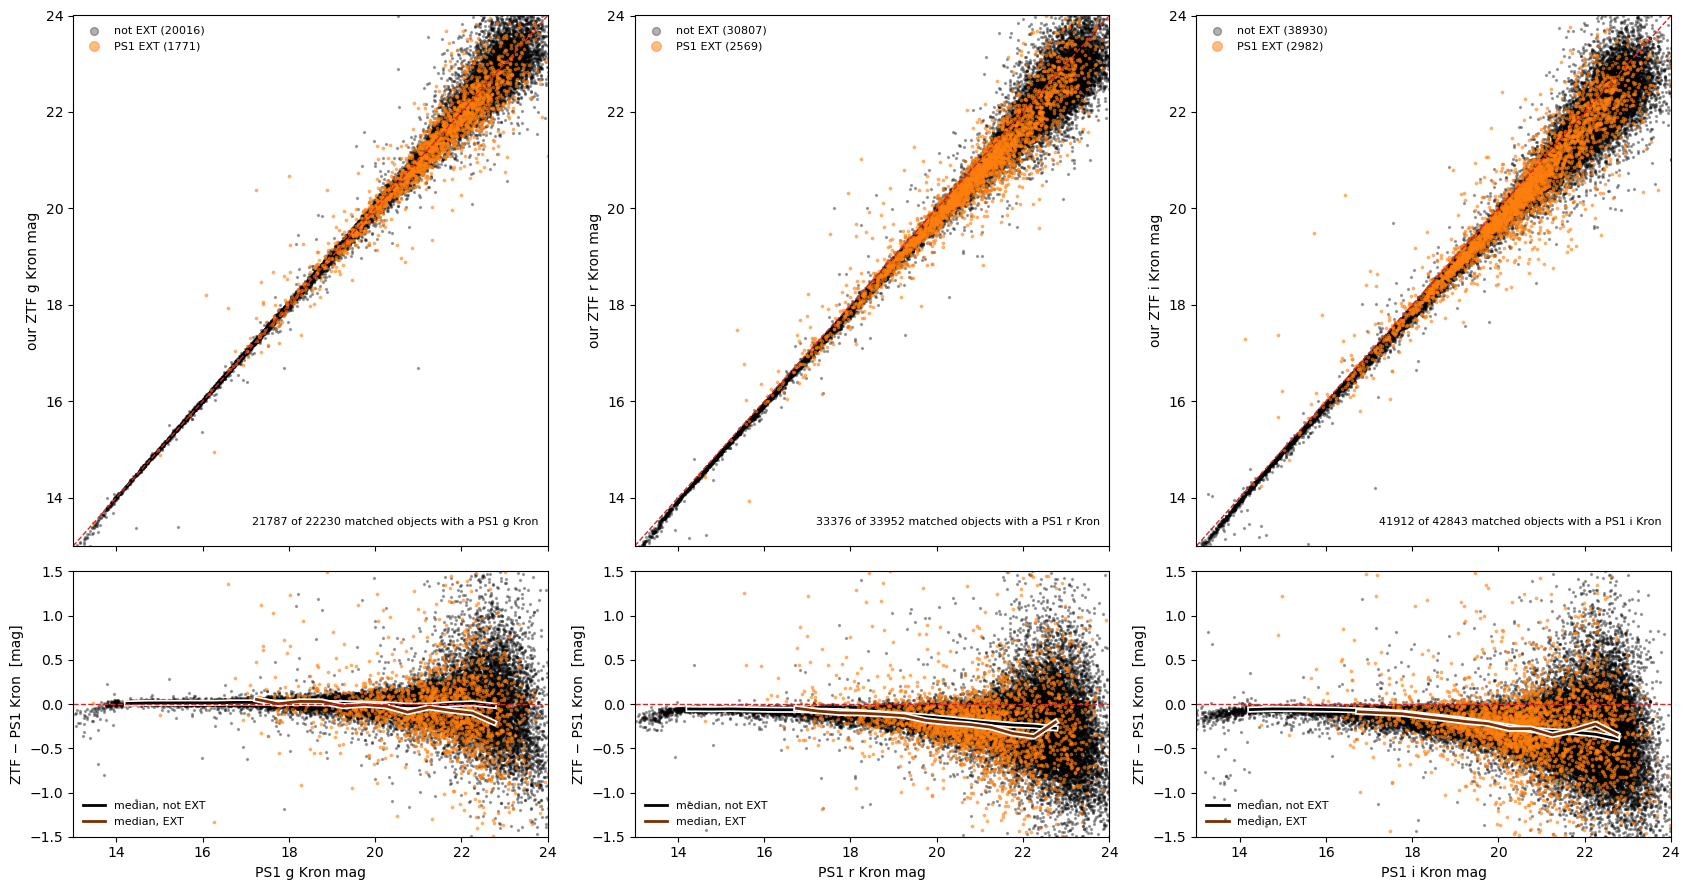

In [7]:
m = obj.ps1_idx.values >= 0; p = ps1.iloc[obj.ps1_idx.clip(lower=0).values]
is_ext = np.where(m, ((p.qualityFlag.astype(int).values & 1) != 0), False)
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex='col', gridspec_kw={'height_ratios': [2, 1]})
for j, bb in enumerate('gri'):
    z = obj[f'{bb}_zkron'].values; pkb = np.where(m, p[f'{bb}KronMag'].values, np.nan)
    f = (obj[f'{bb}_idx'] >= 0).values & m & np.isfinite(z) & np.isfinite(pkb)
    n_ps1 = ((obj[f'{bb}_idx'] >= 0).values & m & np.isfinite(pkb)).sum()
    lim = (13, 24)
    ax = axes[0, j]
    ax.scatter(pkb[f & ~is_ext], z[f & ~is_ext], s=2, alpha=0.3, color='k', label=f'not EXT ({(f & ~is_ext).sum()})')
    ax.scatter(pkb[f & is_ext], z[f & is_ext], s=3, alpha=0.5, color='C1', label=f'PS1 EXT ({(f & is_ext).sum()})')
    ax.plot(lim, lim, 'C3--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim); ax.set_ylabel(f'our ZTF {bb} Kron mag'); ax.legend(frameon=False, markerscale=4, fontsize=8, loc='upper left')
    ax.text(0.98, 0.04, f'{f.sum()} of {n_ps1} matched objects with a PS1 {bb} Kron', transform=ax.transAxes, ha='right', fontsize=8)
    d = z - pkb; ax = axes[1, j]
    ax.scatter(pkb[f & ~is_ext], d[f & ~is_ext], s=2, alpha=0.3, color='k'); ax.scatter(pkb[f & is_ext], d[f & is_ext], s=3, alpha=0.5, color='C1')
    for sel, col, lab in ((f & ~is_ext, 'k', 'median, not EXT'), (f & is_ext, '#7a2d00', 'median, EXT')):
        c, med, n = binned(pkb, d, sel); ax.plot(c[n >= 20], med[n >= 20], '-', color='w', lw=4.5); ax.plot(c[n >= 20], med[n >= 20], '-', color=col, lw=2, label=lab)
    ax.axhline(0, color='C3', ls='--', lw=1); ax.set_ylim(-1.5, 1.5); ax.set_xlabel(f'PS1 {bb} Kron mag'); ax.set_ylabel('ZTF − PS1 Kron  [mag]'); ax.legend(frameon=False, fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()

## Our ZTF Kron against ZTF's published Kron (`refsexcat` `MAG_AUTO`)

IRSA's reference-image products include a SExtractor catalog (`refsexcat.fits`, the "nested-aperture photometry catalog from SExtractor" in the Explanatory Supplement) whose `MAG_AUTO` is SExtractor's Kron-aperture magnitude: elliptical aperture of 2.5 R₁ from the isophotal moments, minimum radius 3.5 px, neighbours corrected by mirroring (`MASK_TYPE CORRECT`). It exists only for sources above SExtractor's detection threshold, about half of the DAOPhot objects, and is matched to them at 1" as `{b}_kron` in the object table. Top: ours against `MAG_AUTO` with the 1:1 line; bottom: the difference against `MAG_AUTO` with running medians; the histogram shows which DAOPhot objects have a `MAG_AUTO` at all.

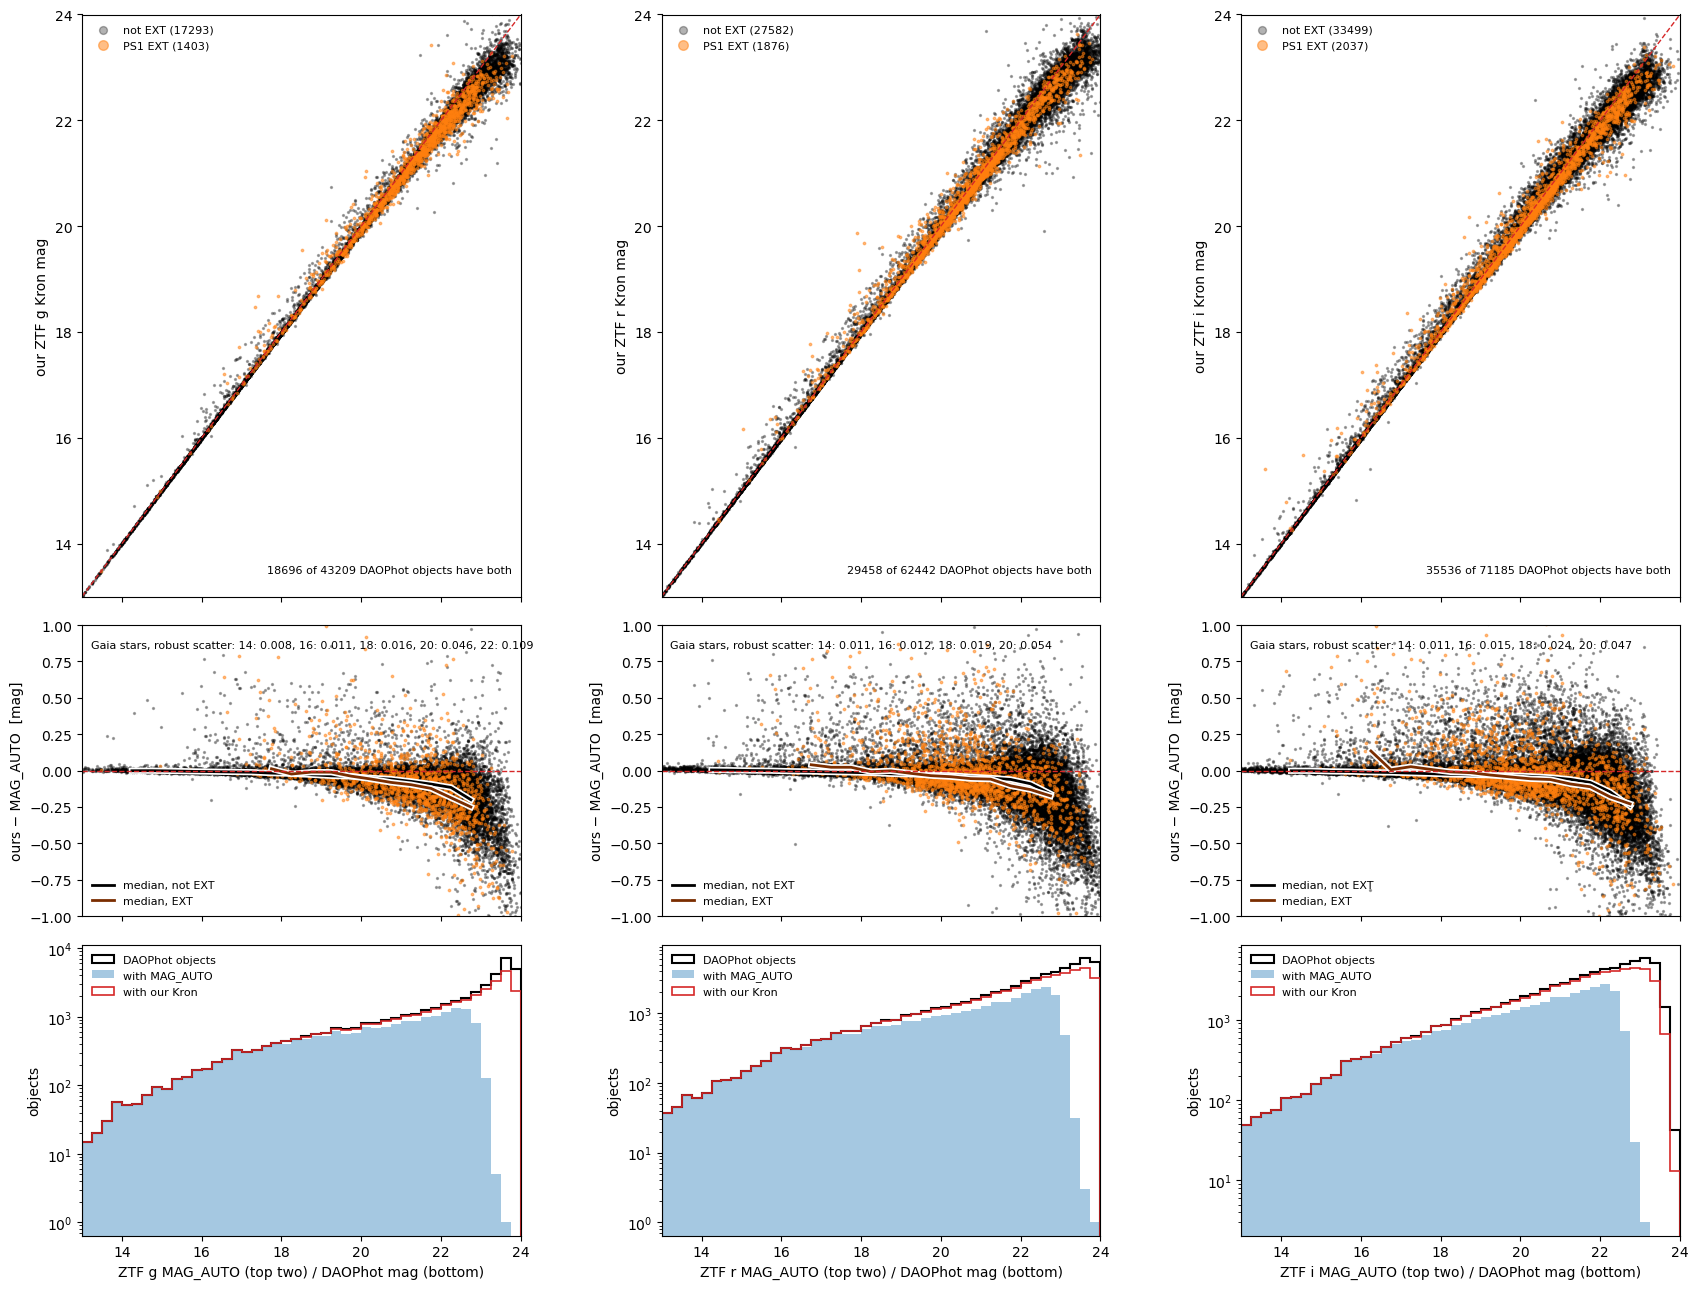

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(17, 13), sharex='col', gridspec_kw={'height_ratios': [2, 1, 1]})
for j, bb in enumerate('gri'):
    detb = (obj[f'{bb}_idx'] >= 0).values
    z, a, magb = obj[f'{bb}_zkron'].values, obj[f'{bb}_kron'].values, obj[f'{bb}_mag'].values
    f = detb & np.isfinite(z) & np.isfinite(a)
    lim = (13, 24)
    ax = axes[0, j]
    ax.scatter(a[f & ~obj.ext.values], z[f & ~obj.ext.values], s=2, alpha=0.3, color='k', label=f'not EXT ({(f & ~obj.ext.values).sum()})')
    ax.scatter(a[f & obj.ext.values], z[f & obj.ext.values], s=3, alpha=0.5, color='C1', label=f'PS1 EXT ({(f & obj.ext.values).sum()})')
    ax.plot(lim, lim, 'C3--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim); ax.set_ylabel(f'our ZTF {bb} Kron mag'); ax.legend(frameon=False, markerscale=4, fontsize=8, loc='upper left')
    ax.text(0.98, 0.04, f'{f.sum()} of {detb.sum()} DAOPhot objects have both', transform=ax.transAxes, ha='right', fontsize=8)
    d = z - a; ax = axes[1, j]
    ax.scatter(a[f & ~obj.ext.values], d[f & ~obj.ext.values], s=2, alpha=0.3, color='k'); ax.scatter(a[f & obj.ext.values], d[f & obj.ext.values], s=3, alpha=0.5, color='C1')
    for sel, col, lab in ((f & ~obj.ext.values, 'k', 'median, not EXT'), (f & obj.ext.values, '#7a2d00', 'median, EXT')):
        c, med, n = binned(a, d, sel); ax.plot(c[n >= 20], med[n >= 20], '-', color='w', lw=4.5); ax.plot(c[n >= 20], med[n >= 20], '-', color=col, lw=2, label=lab)
    s = f & obj.star.values; c, sc, n = binned(a, d, s, mad)
    ax.text(0.02, 0.92, 'Gaia stars, robust scatter: ' + ', '.join(f'{cc:.0f}: {v:.3f}' for cc, v, nn in zip(c, sc, n) if nn >= 30 and cc % 2 == 0.25), transform=ax.transAxes, fontsize=8)
    ax.axhline(0, color='C3', ls='--', lw=1); ax.set_ylim(-1.0, 1.0); ax.set_ylabel('ours − MAG_AUTO  [mag]'); ax.legend(frameon=False, fontsize=8, loc='lower left')
    ax = axes[2, j]
    hb = np.arange(13, 24.01, 0.25)
    ax.hist(magb[detb], bins=hb, histtype='step', color='k', lw=1.5, label='DAOPhot objects')
    ax.hist(magb[detb & np.isfinite(a)], bins=hb, histtype='stepfilled', color='C0', alpha=0.4, label='with MAG_AUTO')
    ax.hist(magb[detb & np.isfinite(z)], bins=hb, histtype='step', color='C3', lw=1.2, label='with our Kron')
    ax.set_yscale('log'); ax.set_xlabel(f'ZTF {bb} MAG_AUTO (top two) / DAOPhot mag (bottom)'); ax.set_ylabel('objects'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## Three-way comparison: what each pipeline actually does

From the sources: psphot (`psphotKronIterate.c`, recipe `ippconfig/recipes/psphot.config`), SExtractor (`photom.c`, settings from the `refsexcat` header: `SEXTHLD 2.5`, `SEXMINAR 1`, `SEXDBLDN 4`, `SEXDBLDC 0.005`, `SEXAPEK1 1.5`, `SEXAPEK3 2.5`), and `Extracting/kron.py`.

| | PS1 (psphot) | ZTF (SExtractor `MAG_AUTO`) | ours |
|---|---|---|---|
| sources | psphot's own detections, PSF-fit | SExtractor detections at 2.5σ (filtered) | DAOPhot `refpsfcat` positions |
| neighbours | all other sources' fitted models subtracted | pixels of other detections mirrored through the centre (`MASK_TYPE CORRECT`) | pixels of other watershed basins masked |
| image for the radius | smoothed, σ = 1.7 px ≈ σ_PSF | detection image, unsmoothed | smoothed, σ = σ_PSF |
| radius statistic | symmetrised first moment, $\sum \mathrm{sign}(f_1)\sqrt{|f_1 f_2|}\,r / \sum \tfrac12(f_1+f_2)$ | plain first moment $\sum f r/\sum f$ in units of the isophotal ellipse | symmetrised first moment, as PS1 |
| window | sky radius, then $\min(6R_1, R_{\rm SB})$, ≥ 4σ_PSF | ellipse of 6 × (A, B) from the isophotal moments | as PS1 |
| aperture | circle, 2.5 R₁ | ellipse, **1.5** R₁ × (A, B), minimum **2.5 × (A, B)** | circle, 2.5 R₁ |
| minimum radius | the PSF stars' own R₁ (≈ 0.8 to 1.2″ here) | 2.5 × A_IMAGE, i.e. 2.5 × the isophotal semi-axis | the stars' own R₁ (1.27″) |
| faint-source cap | R₁ ≤ window if peak S/N < 10 | none | as PS1 |
| pixel sum | whole pixels, unsmoothed image | whole pixels, measurement image | whole pixels, unsmoothed image |
| errors | √Σ variance | √(Σ var + flux/gain) | √Σ `refunc`² |
| aperture correction | none | none (Supplement: not pipeline-calibrated) | none |

The decisive difference is the minimum radius. ZTF's `PHOT_AUTOPARAMS 1.5, 2.5` makes 1.5 R₁ smaller than 2.5 A for essentially every source, so `KRON_RADIUS` sits at its floor of 2.5 for stars and galaxies alike and `MAG_AUTO` is really an isophotal-size aperture, 2.5 × A_IMAGE; since the isophotal semi-axis shrinks with S/N, so does the aperture (3.7″ for 14th-mag stars, 2.3″ at 21.5). PS1's floor is tied to the stars, but its surface-brightness window and faint cap still let the aperture shrink from 3.0″ to 2.1″ over the same range. Ours holds 3.9″ to 3.3″. The cell below measures this, then puts the three pixel-handling schemes on the same aperture to show they agree.

SExtractor KRON_RADIUS at its 2.5 floor for 69% of matched sources


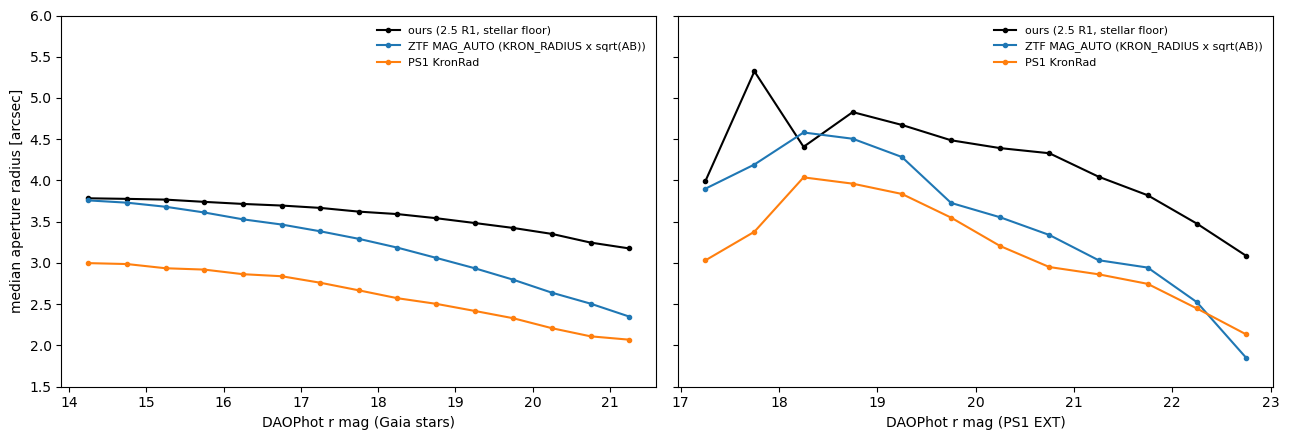

same aperture, different pixel handling (median ± robust scatter): our sum in SExtractor's circle - MAG_AUTO | our sum in PS1's KronRad - PS1 Kron | for reference: PSF - PSF, ours - PS1 Kron
  16-19 stars: SEx circle - AUTO +0.004±0.008 | PS1 circle - PS1 Kron -0.013±0.030 | PSF-PSF -0.062 | ours-PS1 Kron -0.082
  16-19 EXT  : SEx circle - AUTO +0.011±0.020 | PS1 circle - PS1 Kron -0.037±0.073 | PSF-PSF -0.249 | ours-PS1 Kron -0.103
  19-21 stars: SEx circle - AUTO +0.009±0.020 | PS1 circle - PS1 Kron -0.059±0.073 | PSF-PSF -0.098 | ours-PS1 Kron -0.162
  19-21 EXT  : SEx circle - AUTO +0.025±0.043 | PS1 circle - PS1 Kron -0.088±0.097 | PSF-PSF -0.430 | ours-PS1 Kron -0.175
  21-22 stars: SEx circle - AUTO +0.011±0.033 | PS1 circle - PS1 Kron -0.187±0.121 | PSF-PSF -0.199 | ours-PS1 Kron -0.311
  21-22 EXT  : SEx circle - AUTO +0.028±0.060 | PS1 circle - PS1 Kron -0.113±0.161 | PSF-PSF -0.425 | ours-PS1 Kron -0.259


In [9]:
sex = Table.read(refimg_path(f'{D}/ztf_data', *Q, b, 'refsexcat'))['ALPHAWIN_J2000', 'DELTAWIN_J2000', 'KRON_RADIUS', 'A_IMAGE', 'B_IMAGE'].to_pandas()
si, ssep, _ = SkyCoord(obj.ra.values, obj.dec.values, unit='deg').match_to_catalog_sky(SkyCoord(sex.ALPHAWIN_J2000.values, sex.DELTAWIN_J2000.values, unit='deg'))
sx = sex.iloc[si].reset_index(drop=True); has_sex = (ssep < 1 * u.arcsec)
r_sex = np.where(has_sex, (sx.KRON_RADIUS * np.sqrt(sx.A_IMAGE * sx.B_IMAGE)).values * im.pixel_scale, np.nan)   # equivalent circular radius of the MAG_AUTO ellipse
kf = np.where(has_sex, sx.KRON_RADIUS.values, np.nan)
KR = '../Data/ztf_data/ps1_kronrad_643_11_1.parquet'   # PS1 KronRad for this quadrant (MAST stack table), fetched once for this comparison
krad_tab = pd.read_parquet(KR) if os.path.exists(KR) else None
m = obj.ps1_idx.values >= 0; p = ps1.iloc[obj.ps1_idx.clip(lower=0).values]
krad = np.where(m, p[f'{b}KronRad'].values, np.nan) if f'{b}KronRad' in p.columns else (np.where(m, krad_tab.set_index('PanSTARR_ID').reindex(p.PanSTARR_ID.values)[f'{b}KronRad'].values, np.nan) if krad_tab is not None else np.full(len(obj), np.nan))
pk, pmag = np.where(m, p[f'{b}KronMag'].values, np.nan), np.where(m, p[f'{b}PSFMag'].values, np.nan)
r_ours = obj[f'{b}_zkron_rap'].values; ours = obj[f'{b}_zkron'].values; auto = obj[f'{b}_kron'].values; psf = obj[f'{b}_mag'].values
print(f'SExtractor KRON_RADIUS at its 2.5 floor for {100*np.mean(kf[det & has_sex] <= 2.5001):.0f}% of matched sources')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, sel, lab in ((axes[0], star, 'Gaia stars'), (axes[1], ext, 'PS1 EXT')):
    for r_, c_, name in ((r_ours, 'k', 'ours (2.5 R1, stellar floor)'), (r_sex, 'C0', 'ZTF MAG_AUTO (KRON_RADIUS x sqrt(AB))'), (krad, 'C1', 'PS1 KronRad')):
        cc, med, n = binned(mag, r_, sel); ax.plot(cc[n >= 20], med[n >= 20], '.-', color=c_, label=name)
    ax.set_xlabel(f'DAOPhot {b} mag ({lab})'); ax.set_ylim(1.5, 6); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('median aperture radius [arcsec]')
plt.tight_layout(); plt.show()

# same aperture, different pixel handling: our pixel sum inside the other two pipelines' apertures against their magnitudes
def circ(r_arcsec):
    out = np.full(len(obj), np.nan)
    for k in np.flatnonzero(det & np.isfinite(r_arcsec) & frame.inside):
        fl, _, _ = kron.aperture_sum(frame, k, r_arcsec[k] / im.pixel_scale)
        out[k] = im.zero_point - 2.5 * np.log10(fl) if fl > 0 else np.nan
    return out
in_sex, in_ps1 = circ(r_sex), circ(krad)
print("same aperture, different pixel handling (median ± robust scatter): our sum in SExtractor's circle - MAG_AUTO | our sum in PS1's KronRad - PS1 Kron | for reference: PSF - PSF, ours - PS1 Kron")
for lo, hi in ((16, 19), (19, 21), (21, 22)):
    r = det & m & (pmag >= lo) & (pmag < hi)
    for lab, sel in (('stars', r & star), ('EXT  ', r & ext)):
        a = sel & np.isfinite(in_sex) & np.isfinite(auto); c = sel & np.isfinite(in_ps1) & np.isfinite(pk); d = sel & np.isfinite(ours) & np.isfinite(pk)
        print(f'  {lo}-{hi} {lab}: SEx circle - AUTO {np.median((in_sex-auto)[a]):+.3f}±{mad((in_sex-auto)[a]):.3f} | PS1 circle - PS1 Kron {np.median((in_ps1-pk)[c]):+.3f}±{mad((in_ps1-pk)[c]):.3f} | PSF-PSF {np.median((psf-pmag)[d]):+.3f} | ours-PS1 Kron {np.median((ours-pk)[d]):+.3f}')